In [75]:
import numpy as np
import scipy as sc
import matplotlib.pyplot as plt

In [74]:
m = 1
w = 1
hbar = 1
T_0 = 2 * np.pi
epsilon = dt = T_0 / (128)
N_D = 600
x = np.linspace(-4, 4, N_D+1)
alpha = 2

TSN = 200144003
d = int(str(TSN)[-2:])
s = int(str(TSN)[-3])

x_start = ((-1)**s) * (0.5 + (d / 200))

print(f"x_start = {x_start}")

x_start = 0.515


In [24]:
psi_0 = ((alpha / np.pi) ** 0.25) * np.exp((-1 * alpha * (x_arr - x_start)**2) / 2)

## Problem A

In [72]:
time_period = 8 * epsilon
dx = x[1] - x[0]

xa = x[np.newaxis, :]   # shape (1, N), varies along columns
xb = x[:, np.newaxis]   # shape (N, 1), varies along rows
XA, XB = np.meshgrid(x, x)   # both (N, N)

K_amp = np.sqrt(m * w / (2 * np.pi * 1j * hbar * np.sin(w*dt)))
K_phase = (1j * m * w * ((xa**2 + xb**2) * np.cos(w * epsilon) - 2*xa*xb)) / (2 * hbar * np.sin(w * epsilon))

K_eps = K_amp * np.exp(K_phase)

In [73]:
K_8eps = dx**(8-1) * np.linalg.matrix_power(K_eps, 8)
print(K_8eps)

[[-0.05955846+0.0178667j  -0.0757611 +0.0217024j  -0.07967385+0.05414053j
  ... -0.46505982-0.30932634j -0.35439299-0.42735575j
  -0.21687407-0.50917202j]
 [-0.0757611 +0.0217024j  -0.0896081 +0.03330227j -0.08308486+0.06724787j
  ... -0.53404108-0.16837676j -0.46141968-0.31131639j
  -0.35439299-0.42735575j]
 [-0.07967385+0.05414053j -0.08308486+0.06724787j -0.06226964+0.09303051j
  ... -0.56407376-0.01040964j -0.53404108-0.16837676j
  -0.46505982-0.30932634j]
 ...
 [-0.46505982-0.30932634j -0.53404108-0.16837676j -0.56407376-0.01040964j
  ... -0.06226964+0.09303051j -0.08308486+0.06724787j
  -0.07967385+0.05414053j]
 [-0.35439299-0.42735575j -0.46141968-0.31131639j -0.53404108-0.16837676j
  ... -0.08308486+0.06724787j -0.0896081 +0.03330227j
  -0.0757611 +0.0217024j ]
 [-0.21687407-0.50917202j -0.35439299-0.42735575j -0.46505982-0.30932634j
  ... -0.07967385+0.05414053j -0.0757611 +0.0217024j
  -0.05955846+0.0178667j ]]


## Problem B

We can discretize the integral into a sum over 128 time steps to approximate the mean position's evolution.

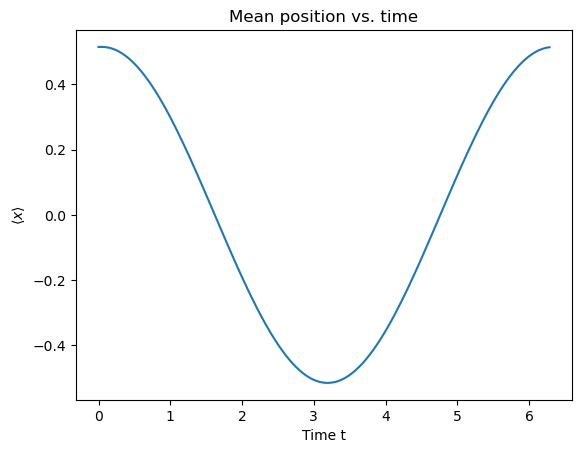

In [96]:
N_steps = 128

psi = np.zeros((N_steps + 1, N_D + 1), dtype=complex)
x_means = np.zeros(N_steps + 1, dtype=complex)

psi[0, :] = psi_0.astype(complex)
x_means[0] = dx * np.dot(x, np.abs(psi[0, :])**2)

for t in range(1, N_steps+1):
    psi[t, :] = dx * (K_eps @ psi[t-1, :])
    x_means[t] = dx * np.dot(x, np.abs(psi[t-1, :]**2))
    
plt.plot(np.arange(N_steps + 1) * epsilon, x_means)
plt.xlabel("Time t")
plt.ylabel(r"$\langle x \rangle$")
plt.title("Mean position vs. time")
plt.show()

## Problem C

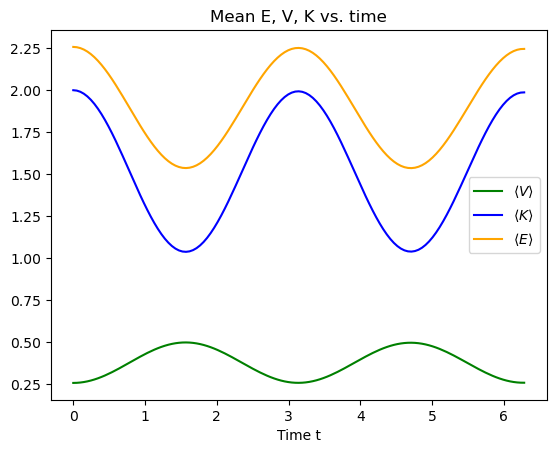

In [95]:
psi = np.zeros((N_steps + 1, N_D + 1), dtype=complex)
V_means = np.zeros(N_steps + 1, dtype=complex)
K_means = np.zeros(N_steps + 1, dtype=complex)
E_means = np.zeros(N_steps + 1, dtype=complex)

psi[0, :] = psi_0.astype(complex)

V_means[0] = (dx / 2) * np.dot(x**2, np.abs(psi[0, :])**2)

for t in range(0, N_steps+1):
    if t != 0:
        psi[t, :] = dx * (K_eps @ psi[t-1])
    
    V_means[t] = (dx / 2) * np.dot(x**2, np.abs(psi[t, :])**2)
    # d(psi)/dx = -alpha * (x - x_start) * psi(x)
    # K_means[t] = dx * (hbar**2 / 2) * np.sum(np.abs(-alpha * np.multiply(x_arr - x_start, psi[t, :]))**2)
    # the above code is wrong because psi may not be gaussian at later times
    # np.gradient finds the 2nd order numerical deriv approximation
    K_means[t] = dx * (hbar**2 / 2) * np.sum(np.abs(-alpha * np.gradient(psi[t, :], dx))**2)
    E_means[t] = V_means[t] + K_means[t]

plt.plot(np.arange(N_steps + 1) * epsilon, V_means, c='green', label=r"$\langle V \rangle$")
plt.plot(np.arange(N_steps + 1) * epsilon, K_means, c='blue', label=r"$\langle K \rangle$")
plt.plot(np.arange(N_steps + 1) * epsilon, E_means, c='orange', label=r"$\langle E \rangle$")
plt.xlabel("Time t")
# plt.ylabel(r"$\langle x \rangle$")
plt.title("Mean E, V, K vs. time")
plt.legend()
plt.show()

## Problem D

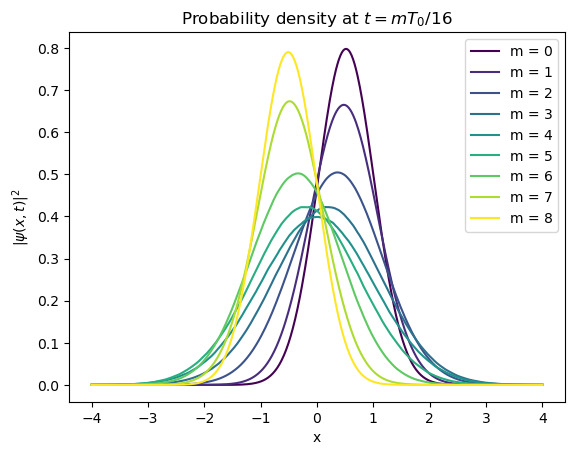

In [111]:
P_list = np.zeros((9, N_D + 1), dtype=complex)
P_list[0, :] = psi_0.astype(complex)

colors = plt.cm.viridis(np.linspace(0, 1, 9))

for m in range(0,9):
    if m != 0:
        # time between updates is 8 epsilons (T_0 / 16)
        psi_new = P_list[m-1, :]
        for _ in range(8):
            psi_new = dx * (K_eps @ psi_new)
        P_list[m, :] = psi_new

    plt.plot(x, np.abs(P_list[m, :])**2, color=colors[m], label=f"m = {m}")

plt.xlabel("x")
plt.ylabel(r"$|\psi(x,t)|^2$")
plt.title(r"Probability density at $t = mT_0/16$")
plt.legend()
plt.show()    

## Problem E

In [103]:
from matplotlib.animation import FuncAnimation, PillowWriter

In [108]:
psi = np.zeros((N_steps + 1, N_D + 1), dtype=complex)
psi[0, :] = psi_0.astype(complex)

for t in range(1, N_steps + 1):
    psi[t, :] = dx * (K_eps @ psi[t-1, :])

prob_amps = np.abs(psi)**2

In [109]:
# Set up the figure with fixed axis limits so the view doesn't jump around
fig, ax = plt.subplots(figsize=(6, 4))
line_prob, = ax.plot([], [], color="tab:blue", label=r"$|\psi|^2$")
line_re,   = ax.plot([], [], color="tab:red", alpha=0.6, lw=1, label=r"Re $\psi$")
time_text = ax.text(0.03, 0.92, "", transform=ax.transAxes)

ymax = max(prob_amps.max(), np.abs(psi.real).max()) * 1.1
ymin = min(0, psi.real.min()) * 1.1
ax.set_xlim(x.min(), x.max())
ax.set_ylim(ymin, ymax)
ax.set_xlabel("x")
ax.set_ylabel(r"$\psi(x,t)$")
ax.set_title("Time evolution over one period")
ax.legend(loc="upper right")

def update(n):
    line_prob.set_data(x, prob_amps[n])
    line_re.set_data(x, psi[n].real)
    time_text.set_text(f"t = {n*epsilon:.3f}  (frame {n}/{N_steps})")
    return line_prob, line_re, time_text

anim = FuncAnimation(fig, update, frames=N_steps + 1, interval=50, blit=True)

anim.save("psi_evolution.gif", writer=PillowWriter(fps=20))

plt.close(fig)

### saving results

In [137]:
import json

results = {
    "tsn": "212345678",
    "x_start": x_start,
    "K8eps_row": {"re": K_8eps[300].real.tolist(),
    "im": K_8eps[300].imag.tolist()},
    "x_mean": x_means.real.tolist(),
    "V": V_means.real.tolist(), "K": K_means.real.tolist(), "E": E_means.real.tolist(),
    "P": [np.real(np.multiply(P_t, np.conjugate(P_t))).tolist() for P_t in P_list],
}

with open("results.json", "w") as f:
    json.dump(results, f)

TypeError: Object of type complex is not JSON serializable